# Freight Rate Prediction — analysis notebook

Predict `posted_rate` for 12,000 loads (Nov–Dec 2025) from 48,000 labelled loads (Jan–Oct 2025).

The notebook runs top to bottom in Google Colab or locally. The modelling code lives in `src/freight/`
so the notebook and the command-line scripts (`src/evaluate.py`, `src/train.py`, `src/predict.py`)
use exactly the same pipeline.

**Sections:** 0 setup · 1 inspect files · 2 EDA · 3 data quality · 4 validation design · 5 model comparison ·
6 residual analysis · 7 final fit and predictions · 8 official scorer and December chart

## 0. Setup
In Colab this clones the repository and installs dependencies. Set `REPO_URL` to your GitHub repo.

In [1]:
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/<your-github-user>/freight-rate-prediction.git"   # <- edit before running in Colab

if IN_COLAB:
    if not Path("freight-rate-prediction").exists():
        !git clone -q {REPO_URL}
    os.chdir("freight-rate-prediction")
    !pip install -q -r requirements.txt
elif Path.cwd().name == "notebooks":
    os.chdir("..")

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
print("Working directory:", ROOT)

Working directory: /home/claude/freight-rate-prediction


The assessment data files are not committed to the repository. Put them in `data/` (the next cell
opens an upload dialog in Colab if any are missing). Hyphenated names from the download
(`train-test.csv`, `validation-predictions-template.csv`, `december-chart-inputs.csv`) are renamed to the
names the code expects.

In [2]:
REQUIRED = {
    "train_test.csv": ["train-test.csv"],
    "validation.csv": [],
    "validation_predictions_template.csv": ["validation-predictions-template.csv"],
    "december_chart_inputs.csv": ["december-chart-inputs.csv"],
}
data_dir = ROOT / "data"
data_dir.mkdir(exist_ok=True)

def missing_files():
    return [f for f in REQUIRED if not (data_dir / f).exists()]

if missing_files() and IN_COLAB:
    from google.colab import files
    print("Upload:", missing_files())
    for name, content in files.upload().items():
        target = next((k for k, alts in REQUIRED.items() if name == k or name in alts), name)
        (data_dir / target).write_bytes(content)

assert not missing_files(), f"Missing data files: {missing_files()}"
print("All data files present:", sorted(p.name for p in data_dir.glob("*.csv")))

All data files present: ['december_chart_inputs.csv', 'train_test.csv', 'validation.csv', 'validation_predictions_template.csv']


In [3]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import importlib, lightgbm, sklearn
from IPython.display import display, Image

from freight import config as C
from freight.data import (load_train, load_validation, daily_market_level, clean_label_mask,
                          segment_ratio, city_table)
from freight import analysis, plots
from freight.models import CANDIDATES, FINAL_MODEL, FreightRateEstimator
from freight.validation import evaluate, SPLITS, ROLLING_WINDOWS

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| sklearn", sklearn.__version__,
      "| lightgbm", lightgbm.__version__, "| seed", C.SEED)

python 3.13.16 | pandas 2.3.3 | sklearn 1.9.1 | lightgbm 4.7.0 | seed 42


## 1. Inspect the project files
Column names, types, target, ids and date ranges, read from the files rather than assumed.

In [4]:
train, val = load_train(), load_validation()
template = pd.read_csv(C.TEMPLATE_FILE)
dec = pd.read_csv(C.DECEMBER_INPUT_FILE)
for name, d in [("train_test.csv", train), ("validation.csv", val), ("template", template), ("december inputs", dec)]:
    print(f"{name:18s} shape={d.shape}  columns={list(d.columns)}")
print("\nTarget column:", C.TARGET, "(only in train_test.csv)")
print("Train dates:", train.date.min().date(), "->", train.date.max().date(),
      "| Validation dates:", val.date.min().date(), "->", val.date.max().date())
print("Template ids identical to validation ids, same order:", (template.load_id.values == val.load_id.values).all())
print("Template predicted_rate all empty:", template.predicted_rate.isna().all())
display(train.head())

train_test.csv     shape=(48000, 14)  columns=['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate']
validation.csv     shape=(12000, 13)  columns=['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal']
template           shape=(12000, 2)  columns=['load_id', 'predicted_rate']
december inputs    shape=(31, 7)  columns=['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']

Target column: posted_rate (only in train_test.csv)
Train dates: 2025-01-01 -> 2025-10-31 | Validation dates: 2025-11-01 -> 2025-12-31
Template ids identical to validation ids, same order: True
Template predicted_rate all empty: True


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


**How `score.py` works (read from the file):**
- `--predictions` must have exactly the columns `load_id,predicted_rate`, 12,000 rows, ids `TE-000001`…`TE-012000`,
  all finite and positive.
- `--december-predictions` must keep the seven columns of `december_chart_inputs.csv` in order, one row per day of
  December 2025, fixed lane Lexington → Fort Wayne, 360 mi, Dry Van, 32,000 lb, positive `predicted_rate`.
- It only validates the format and draws `candidate_december.png`; **no metric is computed locally**
  ("Final validation metrics are calculated by Spotter after submission"). With no official metric given, I
  report MAPE (scale-free, so a $200 short haul and a $6,000 long haul count equally), plus MAE, RMSE, R² and bias.
- The December file lacks coordinates, `market_index` and `quote_signal`; these are filled in section 7.

In [5]:
display(train.describe().T.round(3))
print("Equipment:", train.equipment.value_counts().to_dict())
cities_tr = set(train.pickup) | set(train.delivery); cities_va = set(val.pickup) | set(val.delivery)
print(f"Cities: train {len(cities_tr)}, validation {len(cities_va)}; in validation but never in training: {sorted(cities_va - cities_tr)}")
print("Lexington -> Fort Wayne loads in training:", ((train.pickup == "Lexington") & (train.delivery == "Fort Wayne")).sum())

,count,mean,min,25%,50%,75%,max,std
pickup_lat,48000.0,35.647545,28.35765,31.98691,35.29479,39.41104,44.30296,4.315285
pickup_lon,48000.0,-90.928964,-121.69849,-98.40059,-88.08915,-83.28506,-69.5,13.482431
delivery_lat,48000.0,35.641175,28.35765,31.98691,35.29479,39.41104,44.30296,4.317199
delivery_lon,48000.0,-90.85731,-121.69849,-98.40059,-87.52871,-83.28506,-69.5,13.476589
distance,48000.0,1135.856654,70.0,550.4,953.3,1645.525,3439.8,728.564416
weight,47700.0,31028.844004,-47500.0,25800.0,31436.5,37018.0,47500.0,9391.44062
date,48000,2025-05-31 19:53:29.400000,2025-01-01 00:00:00,2025-03-18 00:00:00,2025-05-31 00:00:00,2025-08-15 00:00:00,2025-10-31 00:00:00,NaN
market_index,47626.0,1.083387,0.67639,0.94967,1.0558,1.21959,1.46778,0.168091
quote_signal,48000.0,2.062468,0.69228,1.89103,2.05575,2.221685,3.61035,0.291391
posted_rate,48000.0,2373.980682,57.22,1251.555,2030.76,3330.75,25533.0,1486.493245


Equipment: {'Dry Van': 27202, 'Reefer': 12045, 'Flatbed': 8753}
Cities: train 64, validation 72; in validation but never in training: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
Lexington -> Fort Wayne loads in training: 32


## 2. Exploratory data analysis
### 2.1 Target and outliers
Rates scale with distance, so I look at rate per mile relative to its equipment × distance-band median.

In [6]:
rpm = train.posted_rate / train.distance
print("Rate per mile quantiles:", rpm.quantile([0, .001, .01, .5, .99, .999, 1]).round(2).to_dict())
ratio = segment_ratio(train)
print("Ratio-to-segment quantiles:", ratio.quantile([.005, .01, .02, .98, .99, .995]).round(3).to_dict())
print("Loads with ratio < 0.6:", (ratio < .6).sum(), "| ratio > 1.6:", (ratio > 1.6).sum(),
      "| between 0.5-0.85 or 1.2-2.0:", ((ratio.between(.5, .85)) | (ratio.between(1.2, 2.0))).sum())
plots.fig_target_outliers(train)

Rate per mile quantiles: {0.0: 0.33, 0.001: 0.44, 0.01: 1.67, 0.5: 2.15, 0.99: 3.18, 0.999: 10.07, 1.0: 14.13}
Ratio-to-segment quantiles: {0.005: 0.344, 0.01: 0.862, 0.02: 0.886, 0.98: 1.129, 0.99: 1.162, 0.995: 2.965}
Loads with ratio < 0.6: 337 | ratio > 1.6: 340 | between 0.5-0.85 or 1.2-2.0: 80


<Figure size 936x390 with 1 Axes>

**Finding.** 98% of loads sit within 0.86–1.16× their segment median. 677 loads (1.4%) sit at 0.17–0.47× or
2.1–5.4×, with almost nothing in between. That clean gap points to corrupted labels (unit or entry errors), not real
expensive lanes, so they are removed from **training** only. Every validation load is still predicted.

### 2.2 Market level, time trend and calendar
`market_index` varies by load. Within a day its spread is small (std ≈ 0.025), so I check whether the daily mean carries the signal.

In [7]:
market = daily_market_level(train, val)
within = train.groupby("date").market_index.std()
print(f"Within-day std of market_index: mean {within.mean():.4f} (range {within.min():.4f}-{within.max():.4f})")
print("Mean market level by month:", market.groupby(market.index.month).mean().round(3).to_dict())

clean, Xc, res = analysis.level_residuals(train, market)
daily = analysis.daily_level_table(clean, Xc, res)
print("\nCorrelation of the daily rate-level residual with:", daily.corr()["residual"].drop("residual").round(3).to_dict())
xd = Xc.assign(r=res)
xd["market_dev"] = xd.market_load - xd.market_day
print("Load-level corr with residual: market deviation from day mean =", round(xd.r.corr(xd.market_dev), 3),
      "| quote_signal =", round(res.corr(clean.quote_signal), 3))
plots.fig_market_and_level(train, val, market, daily["residual"])

Within-day std of market_index: mean 0.0249 (range 0.0205-0.0295)
Mean market level by month: {1: 0.927, 2: 0.997, 3: 1.074, 4: 1.209, 5: 1.3, 6: 1.28, 7: 1.2, 8: 0.98, 9: 0.893, 10: 0.957, 11: 0.919, 12: 0.934}



Correlation of the daily rate-level residual with: {'market': 0.704, 'quote_signal': 0.079, 't': 0.517}
Load-level corr with residual: market deviation from day mean = 0.083 | quote_signal = 0.08


<Figure size 936x598 with 2 Axes>

**Findings.**
- The daily market level explains most of the date-to-date movement (correlation 0.70 with the daily rate residual).
  A load's own deviation from the day's mean adds almost nothing, so the model uses the **daily mean** (built from the
  `market_index` inputs; no labels involved). This also fills missing values and the December file.
- After the market level there is still an upward drift: January rates sit below what the market alone predicts, and
  Sep–Oct sit above. Section 4 shows this is a steady trend of about 0.6% per month.
- `quote_signal` shows no useful relationship with the rate at load or day level. It is kept as an input to the tree
  stage but carries little weight.
- No December data exists in training, so any December-specific (holiday) effect cannot be learned. The validation
  file's December market level is the only December-specific signal.

In [8]:
plots.fig_effects(clean, analysis.level_residuals(train, market, include_weight=False)[2])

<Figure size 936x364 with 2 Axes>

**Findings.** Rate per mile rises steadily with weight, by about 7% from the lightest to the heaviest decile.
Day of week matters a little (midweek ≈ +1%, weekend ≈ −1%). Distance is by far the strongest driver: log rate
correlates 0.90 with distance, and per-mile rates fall on longer hauls. Pickup and delivery cities each shift rates
by about ±3%.

### 2.3 Leakage review

In [9]:
print("Columns available in validation.csv:", list(val.columns))
print("Columns only in training:", sorted(set(train.columns) - set(val.columns)))
# distance vs straight-line distance: a sanity check on the coordinates
from freight.features import haversine_miles
circ = train.distance / haversine_miles(train.pickup_lat, train.pickup_lon, train.delivery_lat, train.delivery_lon)
print("Road distance / straight-line distance:", circ.describe()[["min", "50%", "max"]].round(2).to_dict())
print("Coordinates constant per city:", city_table(train, val).index.is_unique)

Columns available in validation.csv: ['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal']
Columns only in training: ['posted_rate']
Road distance / straight-line distance: {'min': 1.06, '50%': 1.18, 'max': 9.63}
Coordinates constant per city: True


- Every feature used is present in `validation.csv`, so nothing is unavailable at prediction time. `posted_rate` is the
  only training-only column.
- `market_index` is a same-day input supplied with each load. Averaging it per date uses inputs only, never labels.
- The real leakage risks come from learned statistics: city effects, imputation values and outlier limits. All of them
  are fit inside each training fold, and training rows get **out-of-fold** city effects so a row's own label never
  feeds its own feature.
- Coordinates are constant per city but are shifted/clipped synthetic values (e.g. lat 25.5, lon −69.5 caps).
  Road distance is ~1.18× straight-line, as expected, so `distance` is consistent.

## 3. Data-quality issues and treatment

In [10]:
display(analysis.data_quality_table(train, val))

,issue,train,validation,treatment
0,missing weight,300,165,flag + equipment median (fit on training fold)
1,negative weight,292,145,sign error: absolute value + flag
2,"weight at 47,500 cap",1204,301,"censored: kept, flagged"
3,missing market_index,374,249,flag + that date's market level
4,duplicate load_id,0,0,none found
5,corrupted rate label,677,–,dropped from training only (ratio outside 0.6–...


## 4. Validation design

The real task is a **forecast**: train on Jan–Oct and predict Nov–Dec, a 1–2 month horizon past the last label. A
random split would let the model see the same days (and market level) it is tested on, which is not what happens at
submission. So:

| Split | Train | Test | Purpose |
|---|---|---|---|
| Time holdout (model selection) | Jan 1 – Aug 31 | Sep 1 – Oct 31 | same 2-month forward horizon as the task |
| Rolling backtest | expanding from Jan 1 | 5 forward windows | stability across seasons |
| Unseen cities | Jan–Aug, 8 random cities removed | Sep–Oct loads touching those cities | 8 validation cities are new |
| Random 5-fold (seed 42) | random 80% | random 20% | **contrast only**, not used for selection |

Every fold refits the whole estimator on its training part: outlier limits, imputation medians, city effects and
the model. Scores are reported on all test rows and on test rows with clean labels (the outlier limits for the test
rows come from the training part). Corrupted labels can't be predicted by any model, so clean-label MAPE is the
selection metric. All-rows numbers are reported too.

In [11]:
for split in ["holdout", "rolling", "unseen_city"]:
    for fold, tr_idx, te_idx in SPLITS[split](train):
        print(f"{fold[:70]:72s} n_train={len(tr_idx):6,d}  n_test={len(te_idx):6,d}")
print("\nCan the trend be separated from the market in each training window?")
display(analysis.trend_stability(daily))

holdout Jan-Aug -> Sep-Oct                                               n_train=38,477  n_test= 9,523
rolling Jan-Apr -> May-Jun                                               n_train=19,110  n_test= 9,696
rolling Jan-Jun -> Jul-Aug                                               n_train=28,806  n_test= 9,671
rolling Jan-Jul -> Aug-Sep                                               n_train=33,718  n_test= 9,429
rolling Jan-Aug -> Sep-Oct                                               n_train=38,477  n_test= 9,523
rolling Jan-Sep -> Oct                                                   n_train=43,147  n_test= 4,853
unseen cities (Bakersfield, Hartford, Memphis, New York, San Antonio,    n_train=28,431  n_test= 2,516

Can the trend be separated from the market in each training window?


,training window,"corr(market, time)",market coef,trend %/month
0,Jan – Jun,0.86,0.083,1.36
1,Jan – Jul,0.73,0.141,0.69
2,Jan – Aug,0.35,0.160,0.52
3,Jan – Sep,0.03,0.141,0.66
4,Jan – Oct,-0.11,0.142,0.64


This table drives the model choice. With only Jan–Jun data, the market level and time are 0.86 correlated, so a
linear model can't tell trend from market and the trend estimate doubles (1.36%/month). From Jan–Aug onward the
correlation drops and the estimate settles at 0.5–0.7%/month. On the full Jan–Oct window, which the final model is
trained on, the correlation is −0.11, the best identified of all.

## 5. Model comparison
Candidates, all predicting `log(rate / distance)` and converted back to dollars:
1. **Median baseline**: median rate per mile per equipment × distance band.
2. **Ridge**: linear on log distance terms, equipment, weight, market level, trend, day of week, city effects.
3. **Random forest** and 4. **LightGBM**: trees on all features (including the day number).
5. **Ridge + LightGBM on residual**: ridge carries the market level and trend, which extrapolate past the last
   training date; LightGBM models the remaining non-linear structure *without* the day number, so it never has to
   extrapolate time.

Set `RUN_EVALUATION = False` to load saved results from `artifacts/` instead of recomputing (~7 min).

In [12]:
RUN_EVALUATION = True
if RUN_EVALUATION:
    scores, preds = evaluate(train, list(CANDIDATES), ["holdout", "rolling", "unseen_city", "random_kfold"],
                             lambda n: FreightRateEstimator(n, market), keep_predictions=True)
    C.ARTIFACT_DIR.mkdir(exist_ok=True)
    scores.to_csv(C.ARTIFACT_DIR / "cv_scores.csv", index=False)
    summary = (scores.groupby(["split", "subset", "model"])[["MAPE_%", "MAE", "RMSE", "R2", "bias_%", "n_test"]]
               .mean().round(4).reset_index())
    summary.to_csv(C.ARTIFACT_DIR / "cv_summary.csv", index=False)
    preds[preds.split == "holdout"].to_csv(C.ARTIFACT_DIR / "holdout_predictions.csv", index=False)
else:
    scores = pd.read_csv(C.ARTIFACT_DIR / "cv_scores.csv")
    summary = pd.read_csv(C.ARTIFACT_DIR / "cv_summary.csv")

view = summary.pivot_table(index="model", columns=["split", "subset"], values="MAPE_%").round(3)
display(view)

split                holdout              random_kfold               rolling              unseen_city             
subset              all rows clean labels     all rows clean labels all rows clean labels    all rows clean labels
model                                                                                                             
lightgbm               4.602        2.117        3.501        1.118    5.393        2.969       4.816        2.327
median_baseline        6.321        3.817        6.751        4.396    6.722        4.316       6.352        3.819
random_forest          4.751        2.266        3.574        1.192    4.942        2.518       4.935        2.449
ridge                  4.795        2.300        4.208        1.825    5.713        3.226       5.244        2.746
ridge_plus_lightgbm    4.546        2.053        3.706        1.322    5.479        3.001       4.906        2.406

In [13]:
display(summary[(summary.split == "holdout")].set_index(["subset", "model"])
        [["MAPE_%", "MAE", "RMSE", "R2", "bias_%", "n_test"]].round(3))
plots.fig_model_comparison(summary)

MAPE_%      MAE     RMSE     R2  bias_%  n_test
subset       model                                                               
all rows     lightgbm              4.602  109.693  635.307  0.827  -0.139  9523.0
             median_baseline       6.321  138.359  638.843  0.825   0.794  9523.0
             random_forest         4.751  112.816  635.952  0.826  -0.270  9523.0
             ridge                 4.795  109.672  635.029  0.827  -0.296  9523.0
             ridge_plus_lightgbm   4.546  105.315  633.836  0.828  -0.230  9523.0
clean labels lightgbm              2.117   53.848   80.568  0.997  -1.597  9379.0
             median_baseline       3.817   82.778  112.908  0.993  -0.698  9379.0
             random_forest         2.266   56.970   84.433  0.996  -1.730  9379.0
             ridge                 2.300   53.737   79.686  0.997  -1.769  9379.0
             ridge_plus_lightgbm   2.053   49.370   73.029  0.997  -1.696  9379.0

<Figure size 962x377 with 4 Axes>

In [14]:
roll = scores[(scores.split == "rolling") & (scores.subset == "clean labels")]
display(roll.pivot_table(index="fold", columns="model", values="MAPE_%").round(2))
print("Median over rolling windows:", roll.groupby("model")["MAPE_%"].median().round(3).to_dict())
plots.fig_rolling_folds(scores)

model,lightgbm,median_baseline,random_forest,ridge,ridge_plus_lightgbm
fold,,,,,
rolling Jan-Apr -> May-Jun,2.74,6.14,2.17,1.76,1.50
rolling Jan-Aug -> Sep-Oct,2.12,3.82,2.27,2.30,2.05
rolling Jan-Jul -> Aug-Sep,3.53,3.83,2.85,1.99,1.76
rolling Jan-Jun -> Jul-Aug,4.42,3.97,3.09,8.44,8.21
rolling Jan-Sep -> Oct,2.03,3.82,2.21,1.64,1.48


Median over rolling windows: {'lightgbm': 2.739, 'median_baseline': 3.828, 'random_forest': 2.267, 'ridge': 1.988, 'ridge_plus_lightgbm': 1.759}


<Figure size 936x377 with 1 Axes>

**Reading the results.**
- Every learned model beats the median baseline on the average of every forward split. The one per-window exception is Jan–Jun → Jul–Aug, where the two trend-based models (ridge, final) do worse than the baseline.
- On the time holdout, Ridge + LightGBM has the lowest MAPE (2.05% clean labels vs 2.12% LightGBM, 3.82% baseline).
- In the rolling backtest it wins 4 of 5 windows by a clear margin. It loses badly only in Jan–Jun → Jul–Aug, the
  one window whose training data cannot separate trend from market (section 4). That one fold makes the means look
  similar; the median over windows shows the typical case.
- Random 5-fold ranks LightGBM and random forest best (≈1.1%). Those models memorise each day's level, and that
  memorisation is useless for Nov–Dec. This is why random K-fold is not used for selection.
- Unseen cities cost about 0.35 points; the coordinates and the 0-default city effect handle new cities reasonably.

**Decision:** Ridge + LightGBM on residual. It is best where the trend is identifiable, the final training
window is the best-identified one, and it is the only candidate that carries the trend into Nov–Dec. Its
weakness (sensitivity to a short, collinear training window) does not apply to the final fit.

A small grid over ridge alpha and the stage-2 tree size (`src/tune.py`, saved to `artifacts/tuning.csv`) moved MAPE by
under 0.01 points, so the default parameters are kept.

In [15]:
tuning_file = C.ARTIFACT_DIR / "tuning.csv"
if tuning_file.exists():
    t = pd.read_csv(tuning_file)
    display(t.groupby(["alpha", "num_leaves", "n_estimators"])["MAPE_%"].mean().sort_values().round(3).to_frame().head(6))

,,,MAPE_%
alpha,num_leaves,n_estimators,
1.0,63,600,1.758
10.0,63,600,1.762
1.0,31,600,1.763
10.0,31,600,1.763
1.0,63,300,1.764
10.0,63,300,1.766


## 6. Residual analysis (final model, Sep–Oct holdout)

In [16]:
hold = pd.read_csv(C.ARTIFACT_DIR / "holdout_predictions.csv")
h = hold[(hold.model == FINAL_MODEL) & hold.clean].merge(train[["load_id", "date", "distance", "equipment", "pickup"]], on="load_id")
h["pct"] = 100 * (h.pred / h.y - 1)
print("By equipment (MAPE %, bias %):")
display(h.groupby("equipment").pct.agg(MAPE=lambda e: e.abs().mean(), bias="mean", n="size").round(2))
print("Largest absolute % errors on clean labels:", h.pct.abs().quantile([.5, .9, .99, 1]).round(2).to_dict())
plots.fig_holdout_residuals(hold, train)

By equipment (MAPE %, bias %):


,MAPE,bias,n
equipment,,,
Dry Van,1.80,-1.43,5275
Flatbed,2.73,-2.37,1746
Reefer,2.11,-1.79,2358


Largest absolute % errors on clean labels: {0.5: 1.76, 0.9: 4.1, 0.99: 6.93, 1.0: 10.39}


<Figure size 936x364 with 2 Axes>

Errors are flat across distance bands (MAPE 1.98–2.10% in every band from under 250 to over 2,000 miles). By
equipment, Flatbed is the weakest (MAPE 2.73% vs 1.80% Dry Van, 2.11% Reefer) and carries the largest bias (−2.4%).
The dominant error is a **level bias** of about −1.7% with the same sign in every segment: Sep–Oct rates came in a
little above what Jan–Aug implied. That points to a market-level effect, not a segment the model misreads. It is the
main risk for the Nov–Dec forecast and is stated as a limitation in the report.

## 7. Final fit and predictions
Refit on all Jan–Oct labelled data (corrupted labels removed), then predict `validation.csv` and the December file.

In [17]:
import subprocess
for script in ["src/train.py", "src/predict.py"]:
    out = subprocess.run([sys.executable, script], capture_output=True, text=True)
    print(out.stdout, out.stderr)
    assert out.returncode == 0, f"{script} failed"

Trained ridge_plus_lightgbm on 47,323 rows (677 corrupted labels removed).
Trend: 0.64% per month; market level: 0.149 log-units per index point.
Saved -> /home/claude/freight-rate-prediction/artifacts/final_model.joblib
 


Wrote /home/claude/freight-rate-prediction/outputs/validation_predictions.csv (12,000 rows, checks passed)
Wrote /home/claude/freight-rate-prediction/outputs/december_chart_predictions.csv ($828.73 - $856.16)
 


In [18]:
# Strict checks on the deliverable, re-read from disk
pred = pd.read_csv(C.PREDICTIONS_FILE)
tmpl = pd.read_csv(C.TEMPLATE_FILE)
checks = {
    "exactly 12,000 rows": len(pred) == 12_000,
    "columns are load_id,predicted_rate": list(pred.columns) == ["load_id", "predicted_rate"],
    "no missing / non-finite": np.isfinite(pred.predicted_rate).all(),
    "all positive": (pred.predicted_rate > 0).all(),
    "no duplicate ids": pred.load_id.is_unique,
    "same ids, same order as template": (pred.load_id.values == tmpl.load_id.values).all(),
    "every validation id present": set(pred.load_id) == set(val.load_id),
    "no index column written": not any(c.startswith("Unnamed") for c in pred.columns),
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values())
print(pred.predicted_rate.describe().round(2).to_dict())
dec_pred = pd.read_csv(C.DECEMBER_PREDICTIONS_FILE)
print("December file columns:", list(dec_pred.columns))
display(dec_pred.head())

,passed
"exactly 12,000 rows",True
"columns are load_id,predicted_rate",True
no missing / non-finite,True
all positive,True
no duplicate ids,True
"same ids, same order as template",True
every validation id present,True
no index column written,True


{'count': 12000.0, 'mean': 2387.98, 'std': 1379.73, 'min': 193.42, '25%': 1284.79, '50%': 2062.98, '75%': 3391.09, 'max': 6840.78}
December file columns: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']


,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,828.73
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,836.67
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,844.09
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,846.17
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,843.23


In [19]:
# Sanity check on the December lane: the 32 Lexington -> Fort Wayne loads in training, 360 mi, Dry Van
lane = train[(train.pickup == "Lexington") & (train.delivery == "Fort Wayne")]
lane = lane[clean_label_mask(lane, reference=train)]
print(lane.groupby("equipment").agg(n=("posted_rate", "size"), median_rate=("posted_rate", "median"),
                                    median_distance=("distance", "median")).round(1))
print("December predictions (Dry Van, 32,000 lb): min", dec_pred.predicted_rate.min(), "max", dec_pred.predicted_rate.max())

            n  median_rate  median_distance
equipment                                  
Dry Van    21        807.9            362.5
Flatbed     3        877.8            357.8
Reefer      8        934.5            365.8
December predictions (Dry Van, 32,000 lb): min 828.73 max 856.16


## 8. Official scorer and December chart

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: outputs/scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.
 


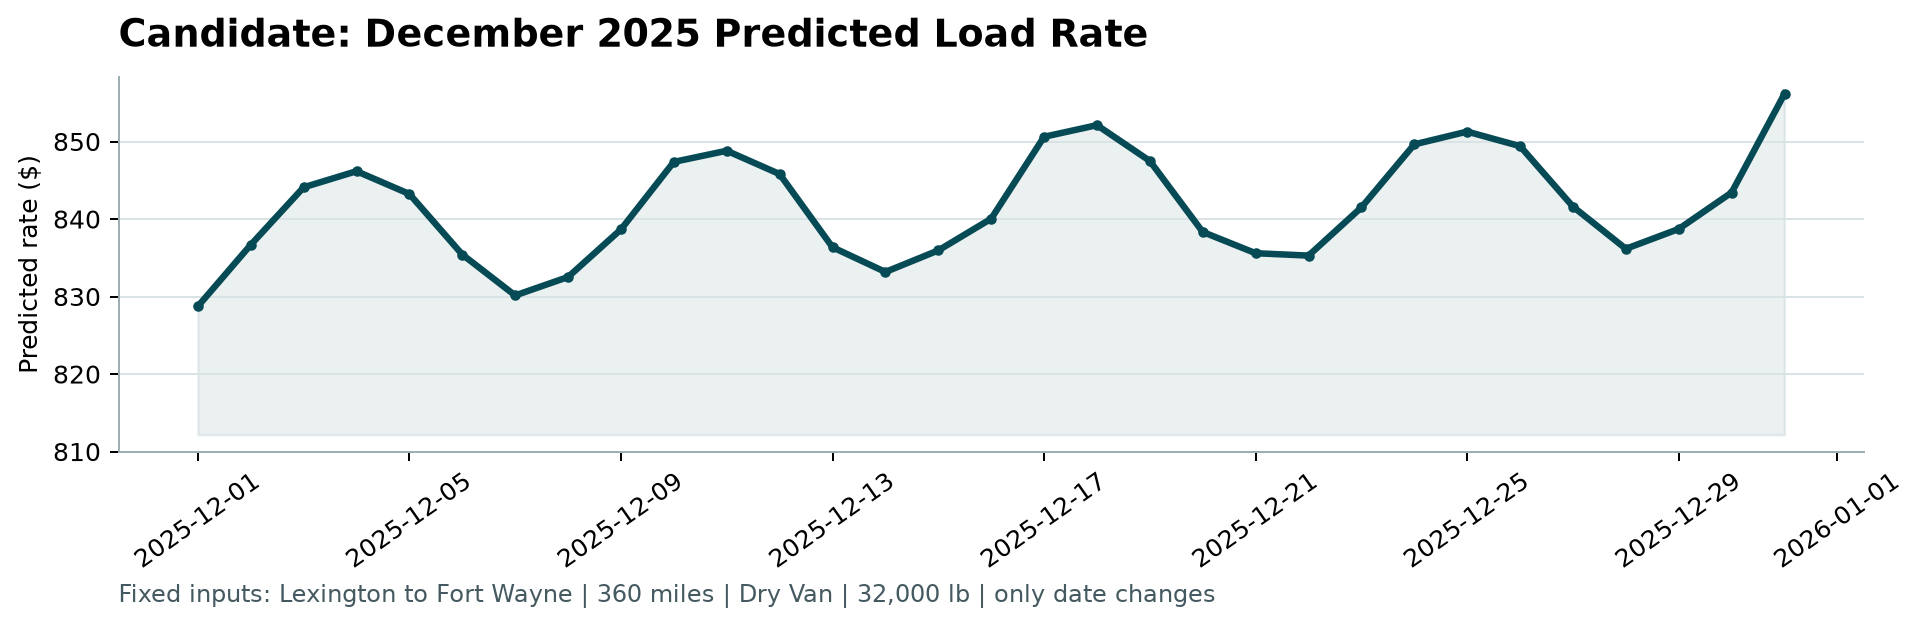

In [20]:
out = subprocess.run([sys.executable, "score.py", "--predictions", str(C.PREDICTIONS_FILE),
                      "--december-predictions", str(C.DECEMBER_PREDICTIONS_FILE),
                      "--output-dir", "outputs/scorer_results"], capture_output=True, text=True)
print(out.stdout, out.stderr); assert out.returncode == 0
display(Image("outputs/scorer_results/candidate_december.png", width=900))

The December chart shows a weekly cycle (midweek peak, weekend dip, learned from the Jan–Oct day-of-week pattern) on a
slight upward drift from the trend and the December market level in `validation.csv`. Christmas is not treated
specially because no December or holiday data exists to learn from.